In [1]:
!pip install sentencepiece

In [2]:
import os, re, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from torch.utils.data import Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import nltk
import time
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from datasets import Dataset

In [3]:
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU: Tesla T4


In [4]:
try:
    df = pd.read_csv('/content/Tweets.csv')
except FileNotFoundError:
    print("Error file not found.")
    exit()

In [5]:
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [6]:
print("\nDataset shape:")
print(df.shape)
print("\nData types:")
print(df.info())


Dataset shape:
(14640, 15)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created      

In [7]:
print("\nSentiment label distribution:")
print(df['airline_sentiment'].value_counts())


Sentiment label distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


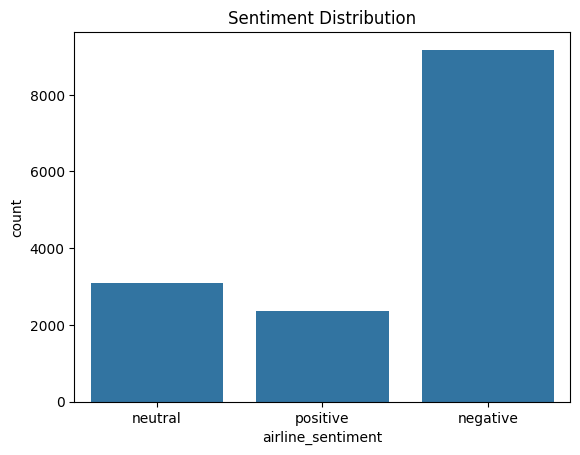

In [8]:
sns.countplot(x='airline_sentiment', data=df)
plt.title('Sentiment Distribution')
plt.show()

In [9]:
stopwords = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '<URL>', text)
    text = re.sub(r'@\w+', '<MENTION>', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'#', '', text)
    text = text.replace("'", "")
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r"\bs\b", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_text)
display(df[['clean_text', 'text']].head())

,clean_text,text
0,what said,@VirginAmerica What @dhepburn said.
1,plus youve added commercials to the experience...,@VirginAmerica plus you've added commercials t...
2,i didnt today must mean i need to take another...,@VirginAmerica I didn't today... Must mean I n...
3,its really aggressive to blast obnoxious enter...,@VirginAmerica it's really aggressive to blast...
4,and its a really big bad thing about it,@VirginAmerica and it's a really big bad thing...


In [10]:
X = df['clean_text']
y = df['airline_sentiment']

# Split into train (70%), val (10%), test (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.67, random_state=42, stratify=y_temp)

print(f'Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}')

Train: 10248 | Val: 1449 | Test: 2943


In [11]:
X_train.head()

,clean_text
5417,suggestions tell customers approximate wait ti...
14211,very upset with my hometown airline stuck in d...
3844,there are exit row window shades in approx 11 ...
3909,hi i am flying domestic first from sea to hnl ...
14271,united needs our ticket number since you reboo...


In [12]:
y_train.head()

,airline_sentiment
5417,negative
14211,negative
3844,negative
3909,neutral
14271,negative


In [13]:
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {0: 'negative', 1: 'neutral', 2: 'positive'}

y_train_enc = y_train.map(label2id).values
y_val_enc   = y_val.map(label2id).values
y_test_enc  = y_test.map(label2id).values

print('Label distribution (train):')
print(pd.Series(y_train_enc).value_counts().rename(id2label))
print('\nLabel distribution (val):')
print(pd.Series(y_val_enc).value_counts().rename(id2label))
print('\nLabel distribution (test):')
print(pd.Series(y_test_enc).value_counts().rename(id2label))

Label distribution (train):
negative    6425
neutral     2169
positive    1654
Name: count, dtype: int64

Label distribution (val):
negative    908
neutral     307
positive    234
Name: count, dtype: int64

Label distribution (test):
negative    1845
neutral      623
positive     475
Name: count, dtype: int64


In [14]:
class TweetDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            padding='max_length',
            max_length=max_len,
            return_tensors='pt'
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

In [15]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average='weighted')
    return {'accuracy': acc, 'f1_weighted': f1}

In [16]:
def train_and_evaluate(model_name, X_train, y_train_enc, X_val, y_val_enc, X_test, y_test_enc,
                        num_labels=3, epochs=3, batch_size=16, lr=2e-5):
    print(f'\n{"="*60}\n  Training: {model_name}\n{"="*60}')
    start = time.time()

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_labels, id2label=id2label, label2id=label2id
    )

    train_dataset = TweetDataset(X_train.values, y_train_enc, tokenizer)
    val_dataset   = TweetDataset(X_val.values,   y_val_enc,   tokenizer)
    test_dataset  = TweetDataset(X_test.values,  y_test_enc,  tokenizer)

    training_args = TrainingArguments(
        output_dir=f'./results/{model_name.replace("/", "_")}',
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        warmup_steps=100,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='no',
        logging_steps=50,
        fp16=False,
        report_to='none'
    )

    trainer = Trainer(
        model=model, args=training_args,
        train_dataset=train_dataset, eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )
    trainer.train()

    # Final evaluation on test set
    preds = np.argmax(trainer.predict(test_dataset).predictions, axis=1)
    acc = accuracy_score(y_test_enc, preds)

    report = classification_report(y_test_enc, preds, target_names=list(id2label.values()), output_dict=True)
    precision = report['weighted avg']['precision']
    recall    = report['weighted avg']['recall']
    f1        = report['weighted avg']['f1-score']

    print(f'\nAccuracy: {acc:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f} | Time: {(time.time()-start)/60:.1f} min')
    print(classification_report(y_test_enc, preds, target_names=list(id2label.values())))

    return {
        'model': model_name, 'accuracy': acc,
        'precision': precision, 'recall': recall, 'f1_weighted': f1,
        'time_min': (time.time()-start)/60, 'preds': preds,
        'cm': confusion_matrix(y_test_enc, preds)
    }

In [17]:
MODEL_LIST = [
    'distilbert-base-uncased',   # Efficient baseline
    'bert-base-uncased',         # Solid standard transformer
    'roberta-base',              # Often stronger than BERT
]

all_results = []

for model_name in MODEL_LIST:
    result = train_and_evaluate(
        model_name,
        X_train, y_train_enc,
        X_val,   y_val_enc,
        X_test,  y_test_enc
    )
    all_results.append(result)


  Training: distilbert-base-uncased


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (20 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted
1,0.464367,0.440762,0.834369,0.836585
2,0.383411,0.422721,0.844030,0.843141
3,0.234261,0.485746,0.846791,0.846061



Accuracy: 0.8502 | Precision: 0.8480 | Recall: 0.8502 | F1: 0.8489 | Time: 12.3 min
              precision    recall  f1-score   support

    negative       0.90      0.92      0.91      1845
     neutral       0.72      0.68      0.70       623
    positive       0.79      0.79      0.79       475

    accuracy                           0.85      2943
   macro avg       0.81      0.80      0.80      2943
weighted avg       0.85      0.85      0.85      2943



In [28]:
results_df = pd.DataFrame([
    {
        'Model':         r['model'].split('/')[-1],
        'Accuracy':      f"{r['accuracy']:.4f}",
        'Precision':     f"{r['precision']:.4f}",
        'Recall':        f"{r['recall']:.4f}",
        'F1 (weighted)': f"{r['f1_weighted']:.4f}",
        'Time (min)':    f"{r['time_min']:.1f}"
    }
    for r in all_results
])

print('\n===== Model Comparison =====')
display(results_df)


===== Model Comparison =====


,Model,Accuracy,Precision,Recall,F1 (weighted),Time (min)
0,distilbert-base-uncased,0.8308,0.8287,0.8308,0.8296,6.4
1,bert-base-uncased,0.8420,0.8405,0.8420,0.8410,12.3
2,roberta-base,0.8502,0.8480,0.8502,0.8489,12.3


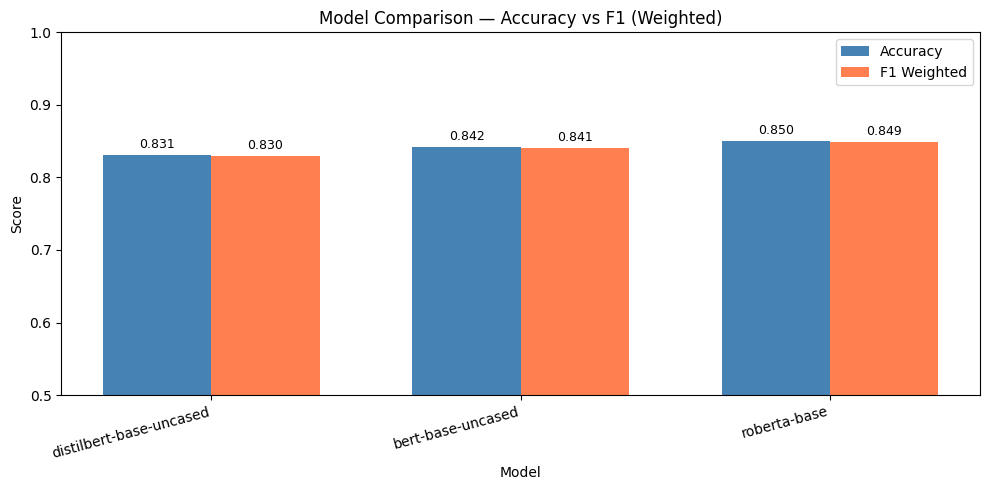

In [24]:
os.makedirs('figures', exist_ok=True)
model_names  = [r['model'].split('/')[-1] for r in all_results]
accuracies   = [r['accuracy']    for r in all_results]
f1_scores    = [r['f1_weighted'] for r in all_results]

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, accuracies, width, label='Accuracy',    color='steelblue')
bars2 = ax.bar(x + width/2, f1_scores,  width, label='F1 Weighted', color='coral')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Accuracy vs F1 (Weighted)')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylim(0.5, 1.0)
ax.legend()
ax.bar_label(bars1, fmt='%.3f', padding=3, fontsize=9)
ax.bar_label(bars2, fmt='%.3f', padding=3, fontsize=9)
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150)
plt.show()

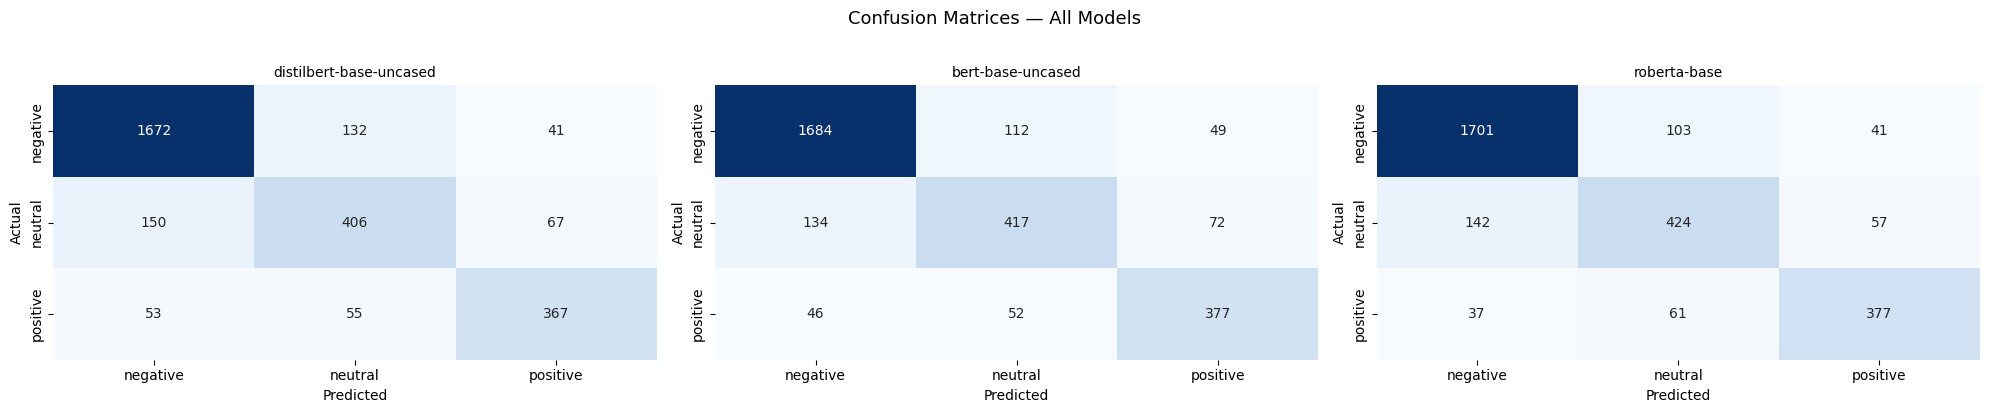

In [25]:
os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
class_names = ['negative', 'neutral', 'positive']

for ax, result in zip(axes, all_results):
    sns.heatmap(
        result['cm'], annot=True, fmt='d', ax=ax,
        xticklabels=class_names, yticklabels=class_names,
        cmap='Blues', cbar=False
    )
    ax.set_title(result['model'].split('/')[-1], fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('figures/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [26]:
# Use the best model's predictions for error analysis
best_result = max(all_results, key=lambda r: r['f1_weighted'])
print(f"Best model: {best_result['model']}")

X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)

error_df = pd.DataFrame({
    'text': X_test_reset,
    'true_label':  [id2label[l] for l in y_test_enc],
    'pred_label':  [id2label[p] for p in best_result['preds']]
})
error_df['correct'] = error_df['true_label'] == error_df['pred_label']
error_df['text_len'] = error_df['text'].apply(len)

mistakes = error_df[~error_df['correct']]

print(f'\nTotal misclassified: {len(mistakes)} / {len(error_df)} ({len(mistakes)/len(error_df)*100:.1f}%)')
print('\n--- Most common confusion pairs ---')
print(mistakes.groupby(['true_label', 'pred_label']).size().sort_values(ascending=False).head(6))

print('\n--- Sample misclassified tweets ---')
display(mistakes[['text', 'true_label', 'pred_label']].sample(10, random_state=42))

Best model: roberta-base

Total misclassified: 441 / 2943 (15.0%)

--- Most common confusion pairs ---
true_label  pred_label
neutral     negative      142
negative    neutral       103
positive    neutral        61
neutral     positive       57
negative    positive       41
positive    negative       37
dtype: int64

--- Sample misclassified tweets ---


,text,true_label,pred_label
465,i sure will,negative,positive
2936,twitter isnt letting me dm you,neutral,negative
961,im sure a lot of your 747 and 777 jfk lhr flig...,positive,neutral
1906,who is he i must send a note too good for words,positive,neutral
2653,all up to date cant update via google play,neutral,negative
2658,this is not a local united number for malaysia...,neutral,negative
1499,thanks got put on the am flight tomorrow dont ...,positive,negative
742,lol i was sure id wake up to more of a respons...,negative,positive
2720,is there a direct number to call to request a ...,neutral,negative
2673,sprinted from c concourse to e and just made i...,neutral,negative
